In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from mlxtend.preprocessing import TransactionEncoder
# print(dir(preprocessing))

In [4]:
from mlxtend.frequent_patterns import apriori,association_rules

# print(dir(frequent_patterns))

In [9]:
pip install mlxtend

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [5]:
df=pd.read_csv("Market_Basket_Optimisation.csv",header=None)

In [6]:
df.head(5)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# convert this into list

transactions=[]
for i in range(len(df)):
    items=df.iloc[i].dropna().tolist();
    items=[item.strip() for item in items if str(item).strip()!=""]
    transactions.append(items)

In [12]:
transactions[:5]

[['shrimp',
  'almonds',
  'avocado',
  'vegetables mix',
  'green grapes',
  'whole weat flour',
  'yams',
  'cottage cheese',
  'energy drink',
  'tomato juice',
  'low fat yogurt',
  'green tea',
  'honey',
  'salad',
  'mineral water',
  'salmon',
  'antioxydant juice',
  'frozen smoothie',
  'spinach',
  'olive oil'],
 ['burgers', 'meatballs', 'eggs'],
 ['chutney'],
 ['turkey', 'avocado'],
 ['mineral water', 'milk', 'energy bar', 'whole wheat rice', 'green tea']]

In [8]:
te=TransactionEncoder()

data=te.fit(transactions).transform(transactions)

print(data[:5])

[[ True  True False  True False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False  True False False False
  False False  True False False False False False False False False  True
  False False False False  True  True False False False False False  True
  False False False False  True False False False False False False  True
  False False False False False False False False  True False False False
  False False False False False False  True  True False False False False
   True False False False False  True False False False  True False False
  False False  True False False  True False False  True False False]
 [False False False False False False False False False False False False
  False False  True False False False False False False False False False
  False False False False False False False False False False False False
   True False False False False False False

In [9]:
df=pd.DataFrame(data,columns=te.columns_)
df.head(5)

,almonds,antioxydant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea,blueberries,body spray,...,turkey,vegetables mix,water spray,white wine,whole weat flour,whole wheat pasta,whole wheat rice,yams,yogurt cake,zucchini
0,True,True,False,True,False,False,False,False,False,False,...,False,True,False,False,True,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,True,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False


In [10]:
# frequent item

frequent_item=apriori(df,min_support=0.01,use_colnames=True);

print("frequent Item set")
print(frequent_item)

frequent Item set
      support                                 itemsets
0    0.020397                                (almonds)
1    0.033329                                (avocado)
2    0.010799                         (barbecue sauce)
3    0.014265                              (black tea)
4    0.011465                             (body spray)
..        ...                                      ...
252  0.011065       (mineral water, milk, ground beef)
253  0.017064  (mineral water, spaghetti, ground beef)
254  0.015731         (spaghetti, milk, mineral water)
255  0.010265    (spaghetti, olive oil, mineral water)
256  0.011465     (pancakes, spaghetti, mineral water)

[257 rows x 2 columns]


In [11]:
# generate association rule
rules=association_rules(frequent_item,metric="confidence",min_threshold=0.1)

In [12]:
print("Association Rules")
print(rules)

Association Rules
                    antecedents                 consequents  \
0                     (avocado)             (mineral water)   
1                        (cake)                   (burgers)   
2                     (burgers)                      (cake)   
3                   (chocolate)                   (burgers)   
4                     (burgers)                 (chocolate)   
..                          ...                         ...   
315                 (olive oil)  (spaghetti, mineral water)   
316       (pancakes, spaghetti)             (mineral water)   
317   (pancakes, mineral water)                 (spaghetti)   
318  (spaghetti, mineral water)                  (pancakes)   
319                  (pancakes)  (spaghetti, mineral water)   

     antecedent support  consequent support   support  confidence      lift  \
0              0.033329            0.238368  0.011598    0.348000  1.459926   
1              0.081056            0.087188  0.011465    0.141447  

In [19]:
print(rules[['antecedents','consequents','support','confidence','lift']])

                    antecedents                 consequents   support  \
0                     (avocado)             (mineral water)  0.011598   
1                        (cake)                   (burgers)  0.011465   
2                     (burgers)                      (cake)  0.011465   
3                   (chocolate)                   (burgers)  0.017064   
4                     (burgers)                 (chocolate)  0.017064   
..                          ...                         ...       ...   
315                 (olive oil)  (mineral water, spaghetti)  0.010265   
316   (mineral water, pancakes)                 (spaghetti)  0.011465   
317  (mineral water, spaghetti)                  (pancakes)  0.011465   
318       (pancakes, spaghetti)             (mineral water)  0.011465   
319                  (pancakes)  (mineral water, spaghetti)  0.011465   

     confidence      lift  
0      0.348000  1.459926  
1      0.141447  1.622319  
2      0.131498  1.622319  
3      0.10

In [13]:
print("Evaluation Matrix")

print("Average Support:",rules['support'].mean())
print("Average Confidence:",rules['confidence'].mean())
print("Average Lift:",rules['lift'].mean())


Evaluation Matrix
Average Support: 0.018403379549393414
Average Confidence: 0.21765732721123437
Average Lift: 1.563006203877658


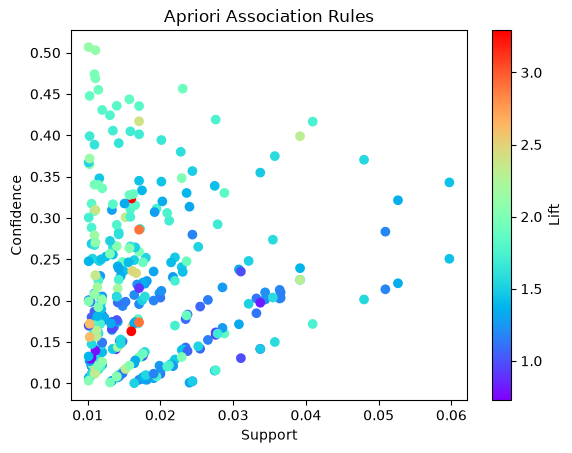

In [14]:
plt.scatter(rules['support'], rules['confidence'],
            c=rules['lift'], cmap='rainbow')

plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Apriori Association Rules")
plt.colorbar(label='Lift')
plt.show()

In [4]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\Admin\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


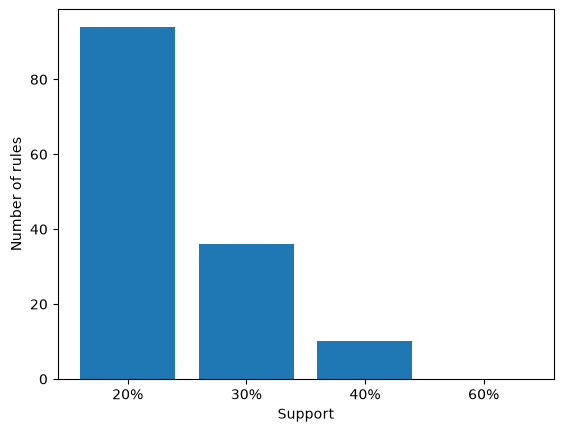

In [15]:
support_values=[0.02,0.03,0.04,0.06]
counts=[]
for value in support_values:
    count=(rules['support']>=value).sum()
    counts.append(count)

plt.bar(['20%','30%','40%','60%'],counts)
plt.xlabel("Support")
plt.ylabel("Number of rules")
plt.show()

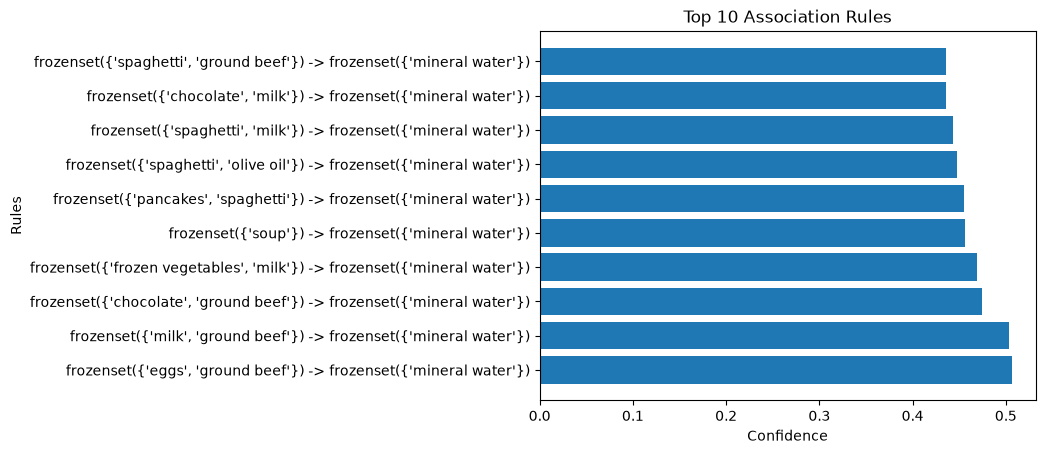

In [17]:
top10 = rules.sort_values(by='confidence',ascending=False).head(10)
labels=top10['antecedents'].astype(str)+' -> '+top10['consequents'].astype(str)

plt.barh(labels, top10['confidence'])
plt.xlabel("Confidence")
plt.ylabel("Rules")
plt.title("Top 10 Association Rules")
plt.show()